In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
from scipy.special import gammaln, factorial
from scipy.stats import poisson


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.precision", 3)

In [2]:
file_path = Path("pl_matches_all_seasons_clean.parquet")
if not file_path.exists():
    file_path = Path("data/processed/premier_league/pl_matches_all_seasons_clean.parquet")
df = pd.read_parquet(file_path)


In [3]:
df.shape

(6930, 116)

In [4]:
feature_cols = [
    "elo_difference",
    "home_goals_scored_roll5",
    "home_goals_conceded_roll5",
    "away_goals_scored_roll5",
    "away_goals_conceded_roll5",

    "home_goals_scored_roll10",
    "home_goals_conceded_roll10",
    "away_goals_scored_roll10",
    "away_goals_conceded_roll10",

    "home_venue_goals_scored_roll5",
    "home_venue_goals_conceded_roll5",
    "away_venue_goals_scored_roll5",
    "away_venue_goals_conceded_roll5",

    "home_sot_roll5",
    "away_sot_roll5",

    "home_rest_days",
    "away_rest_days",
    "home_prior_matches_count",
    "away_prior_matches_count",
]

print("Number of selected features:", len(feature_cols))

Number of selected features: 19

In [5]:
# Poisson model: predict home and away goals
goal_target_cols = [
    "target_full_time_home_goals",
    "target_full_time_away_goals"
]

# 1X2 model: predict home win, draw, or away win
result_target_col = "target_full_time_result"

# Binary market prediction targets
over25_target_col = "target_over_2_5"
btts_target_col = "target_btts"

target_cols = (
    goal_target_cols
    + [
        result_target_col,
        over25_target_col,
        btts_target_col
    ]
)

print("Number of target variables:", len(target_cols))
print(target_cols)

Number of target variables: 5
['target_full_time_home_goals', 'target_full_time_away_goals', 'target_full_time_result', 'target_over_2_5', 'target_btts']

In [6]:
completed_df = df.dropna(
    subset=goal_target_cols
).copy()


print("Original dataset:", len(df))
print("Completed matches:", len(completed_df))
print("Excluded rows:", len(df) - len(completed_df))

Original dataset: 6930
Completed matches: 6930
Excluded rows: 0

In [7]:
# Input feature matrix
X = completed_df[feature_cols].copy()

# Goal prediction targets
y_goals = completed_df[goal_target_cols].copy()

# Match result target
y_1x2 = completed_df[result_target_col].copy()

# Over 2.5 target
y_over25 = completed_df[over25_target_col].copy()

# Both teams to score target
y_btts = completed_df[btts_target_col].copy()

print("X:", X.shape)
print("Y goals:", y_goals.shape)
print("Y 1X2:", y_1x2.shape)
print("Y Over 2.5:", y_over25.shape)
print("Y BTTS:", y_btts.shape)

X: (6930, 19)
Y goals: (6930, 2)
Y 1X2: (6930,)
Y Over 2.5: (6930,)
Y BTTS: (6930,)

In [8]:
# 2. Extract standard 'YYYY/YYYY' season_name for matching
completed_df["season_name"] = completed_df["season_id"].str.extract(r'(\d{4})-(\d{4})').apply(lambda r: f"{r[0]}/{r[1]}", axis=1)

# 3. Define Train & Test Seasons
train_seasons = [
    # Historical Era
    "2008/2009", "2009/2010", "2010/2011", "2011/2012",
    "2012/2013", "2013/2014", "2014/2015", "2015/2016",
    # Modern Era
    "2016/2017", "2017/2018", "2018/2019", "2019/2020",
    "2020/2021", "2021/2022", "2022/2023", "2023/2024"
]

test_seasons = [
    "2024/2025",
    "2025/2026"
]

train_mask = completed_df["season_name"].isin(train_seasons)
test_mask = completed_df["season_name"].isin(test_seasons)

# Split X
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

# Split Y
y_goals_train = y_goals.loc[train_mask].copy()
y_goals_test = y_goals.loc[test_mask].copy()

y_1x2_train = y_1x2.loc[train_mask].copy()
y_1x2_test = y_1x2.loc[test_mask].copy()

y_over25_train = y_over25.loc[train_mask].copy()
y_over25_test = y_over25.loc[test_mask].copy()

y_btts_train = y_btts.loc[train_mask].copy()
y_btts_test = y_btts.loc[test_mask].copy()

print("Feature matrix shape:", X.shape)
print("Training matches:    ", f"{len(X_train):,} ({train_seasons[0]} to {train_seasons[-1]})")
print("Testing matches:     ", f"{len(X_test):,} ({test_seasons[0]} to {test_seasons[-1]})")
print("Nulls in X_train:    ", X_train.isnull().sum().sum())
print("Nulls in X_test:     ", X_test.isnull().sum().sum())

Feature matrix shape: (6930, 19)
Training matches:     6,080 (2008/2009 to 2023/2024)
Testing matches:      760 (2024/2025 to 2025/2026)
Nulls in X_train:     0
Nulls in X_test:      0

In [9]:
imputer = SimpleImputer(strategy="median")

# Fit only on training features; apply the same medians to test features.
X_train = imputer.fit_transform(X_train).astype(np.float32)
X_test = imputer.transform(X_test).astype(np.float32)

print("Imputation completed.")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Imputation completed.
X_train: (6080, 19)
X_test: (760, 19)

## Model-ready arrays

The split and preprocessing steps above use DataFrames for convenient column selection. The following cell converts every training and test set to NumPy arrays for numerical model operations.

In [10]:
# Feature matrices
X_train = X_train.astype(np.float32, copy=False)
X_test = X_test.astype(np.float32, copy=False)

# Goal-count targets: two columns [home_goals, away_goals]
y_goals_train = y_goals_train.to_numpy(dtype=np.float32)
y_goals_test = y_goals_test.to_numpy(dtype=np.float32)

# Other targets
y_1x2_train = y_1x2_train.to_numpy()
y_1x2_test = y_1x2_test.to_numpy()

y_over25_train = y_over25_train.to_numpy()
y_over25_test = y_over25_test.to_numpy()

y_btts_train = y_btts_train.to_numpy()
y_btts_test = y_btts_test.to_numpy()

print("X_train:", X_train.shape, X_train.dtype)
print("X_test:", X_test.shape, X_test.dtype)
print("y_goals_train:", y_goals_train.shape, y_goals_train.dtype)
print("y_goals_test:", y_goals_test.shape, y_goals_test.dtype)
print("y_1x2_train:", y_1x2_train.shape, y_1x2_train.dtype)
print("y_1x2_test:", y_1x2_test.shape, y_1x2_test.dtype)
print("y_over25_train:", y_over25_train.shape, y_over25_train.dtype)
print("y_over25_test:", y_over25_test.shape, y_over25_test.dtype)
print("y_btts_train:", y_btts_train.shape, y_btts_train.dtype)
print("y_btts_test:", y_btts_test.shape, y_btts_test.dtype)

X_train: (6080, 19) float32
X_test: (760, 19) float32
y_goals_train: (6080, 2) float32
y_goals_test: (760, 2) float32
y_1x2_train: (6080,) object
y_1x2_test: (760,) object
y_over25_train: (6080,) int64
y_over25_test: (760,) int64
y_btts_train: (6080,) int64
y_btts_test: (760,) int64

# MatchLab — Dataset Notes

## 1. Inputs (`X`)

The model receives 19 pre-match features. `home_` and `away_` describe the teams in the **current fixture row**, not fixed clubs.

| Feature group | Columns | What they represent |
|---|---|---|
| Team strength | `elo_difference` | Home Elo minus away Elo. Positive means the home team has the higher rating. |
| Recent form | `*_goals_scored_roll5`, `*_goals_conceded_roll5` | Average goals scored/conceded over the previous 5 matches. |
| Longer form | `*_goals_scored_roll10`, `*_goals_conceded_roll10` | The same measures over the previous 10 matches. |
| Venue form | `*_venue_goals_scored_roll5`, `*_venue_goals_conceded_roll5` | Previous 5 home matches for the home side; previous 5 away matches for the away side. |
| Attacking activity | `home_sot_roll5`, `away_sot_roll5` | Average shots on target over the previous 5 matches. |
| Rest and experience | `*_rest_days`, `*_prior_matches_count` | Days since the previous match and the number of prior matches. |

**Rolling-window reminder:** `roll5` and `roll10` summarize recent history. All features for a fixture must use information available before its kickoff.

## 2. Targets (`y`)

Targets are outcomes observed after the match. They must never be included in `X`.

| Target variable | Meaning | Intended task |
|---|---|---|
| `y_goals` | Home and away full-time goals | Predict each team's goal count / expected goals |
| `y_1x2` | `H`, `D`, or `A` | Home win, draw, or away win |
| `y_over25` | `1` if total goals exceed 2.5, otherwise `0` | Over 2.5 classification |
| `y_btts` | `1` if both teams score, otherwise `0` | Both-teams-to-score classification |

For the goal model, the two columns of `y_goals` correspond to home goals first and away goals second.

## 3. Preparation and split

- Rows without either full-time goal target are excluded.
- Matches are sorted by kickoff time.
- Seasons 2008/09–2023/24 are used for training; 2024/25–2025/26 are used for testing.
- The median imputer is fitted on `X_train` only. The learned medians are then applied to `X_test`.

## 4. NumPy arrays and shapes

After preprocessing, the model-ready data is converted to NumPy arrays:

| Array | Shape | Contents |
|---|---|---|
| `X_train` | `(n_train, 19)` | Training features |
| `X_test` | `(n_test, 19)` | Test features |
| `y_goals_train` | `(n_train, 2)` | Home and away goal targets |
| `y_goals_test` | `(n_test, 2)` | Home and away goal targets |
| `y_1x2_train/test` | `(n,)` | Match-result labels |
| `y_over25_train/test` | `(n,)` | Over 2.5 labels |
| `y_btts_train/test` | `(n,)` | BTTS labels |

**Home Model**

In [11]:
#standardizing the features ( high value features affect the model more agressively)
X_mean = np.mean(X_train, axis=0)
X_std = np.std(X_train, axis=0)
X_std[X_std == 0] = 1
X_train = (X_train - X_mean)/ X_std
X_test = (X_test - X_mean)/ X_std

In [12]:
row , col = X_train.shape
rng = np.random.default_rng(42)

beta_h = rng.normal(0, 0.01, size=col)
beta_intercept = 0.00234
home_goals =  y_goals_train[:, 0]
home_goals_test = y_goals_test[:, 0]

away_goals = y_goals_train[:, 1]
away_goals_test = y_goals_test[:, 1]

In [13]:
z = beta_intercept + X_train @ beta_h
lamda = np.exp(z)

log_fact = gammaln(home_goals + 1)

nll = np.mean(
    lamda - (home_goals * z) + log_fact
)

print(nll)

1.742347

In [14]:
lr = 0.01
for _ in range(5000):
  #gradient calculation
  grad = (X_train.T @ (lamda- home_goals)) / row
  grad_intercept = (np.sum(lamda- home_goals)) / row

  beta_h -= lr * grad
  beta_intercept -= lr * grad_intercept

  z = beta_intercept + X_train @ beta_h
  lamda = np.exp(np.clip(z, -10, 10))

log_fact = gammaln(home_goals + 1)
nll = np.mean(lamda - (home_goals*z) + log_fact)
print(nll)

1.518345

In [15]:
baseline_lambda = np.mean(home_goals)

baseline_nll = np.mean(
    baseline_lambda
    - home_goals * np.log(baseline_lambda)
    + gammaln(home_goals + 1)
)

print("Home Baseline NLL:", baseline_nll)

Home Baseline NLL: 1.5968

In [16]:
z_test = beta_intercept + X_test @ beta_h
lamda_test_h = np.exp(z_test)
log_fact_h = gammaln(home_goals_test + 1)
nll_test_h = np.mean(lamda_test_h - (home_goals_test * z_test) + log_fact_h)
print("Home Test nll: ", nll_test_h)

Home Test nll:  1.5062

In [17]:
baseline_lambda = np.mean(home_goals)
test_baseline_nll = np.mean(
    baseline_lambda
    - home_goals_test * np.log(baseline_lambda)
    + gammaln(home_goals_test + 1)
)

print("Home Test baseline:", test_baseline_nll)

Home Test baseline: 1.5507

**Away model**

In [18]:
row , col = X_train.shape
rng = np.random.default_rng(42)

beta_a = rng.normal(0, 0.01, size=col)
beta_intercept_a = 0.00234

away_goals = y_goals_train[:, 1]
away_goals_test = y_goals_test[:, 1]

In [19]:
z = beta_intercept_a + X_train @ beta_a
lamda_a = np.exp(z)

log_fact = gammaln(away_goals + 1)
nll = np.sum(lamda_a - (away_goals*np.log(lamda_a)) + log_fact) / row
print(nll)

1.474718

In [20]:
lr = 0.01
for _ in range(5000):
  #gradient calculation
  grad = (X_train.T @ (lamda_a- away_goals)) / row
  grad_intercept = (np.sum(lamda_a- away_goals)) / row

  beta_a -= lr * grad
  beta_intercept_a-= lr * grad_intercept

  z = beta_intercept_a + X_train @ beta_a
  lamda_a = np.exp(np.clip(z, -10, 10))

log_fact = gammaln(away_goals + 1)
nll = np.mean(lamda_a - (away_goals*z) + log_fact)
print("Away model nll: ", nll)

Away model nll:  1.3944

In [21]:
baseline_lambda = np.mean(away_goals)

baseline_nll = np.mean(
    baseline_lambda
    - away_goals * np.log(baseline_lambda)
    + gammaln(away_goals + 1)
)

print("Away Baseline NLL:", baseline_nll)

Away Baseline NLL: 1.4602

In [22]:
z_test = beta_intercept_a + X_test @ beta_a
lamda_test_a = np.exp(z_test)
log_fact_a = gammaln(away_goals_test + 1)
nll_test_a = np.mean(lamda_test_a - (away_goals_test * z_test) + log_fact_a)
print("Away Test nll: " ,nll_test_a)

Away Test nll:  1.4185

In [23]:
baseline_lambda = np.mean(away_goals)
test_baseline_nll = np.mean(
    baseline_lambda
    - away_goals_test * np.log(baseline_lambda)
    + gammaln(away_goals_test + 1)
)

print("Away Test baseline:", test_baseline_nll)

Away Test baseline: 1.4625

**Score line probability**

In [24]:
from scipy.special import factorial
k = np.arange(5).reshape(1, -1)
lamda_h_t = lamda_test_h.reshape(-1, 1)
lamda_a_t = lamda_test_a.reshape(-1, 1)

prob_h = (np.exp(-lamda_h_t) * (lamda_h_t**k)) / factorial(k)
prob_a = (np.exp(-lamda_a_t) * (lamda_a_t**k)) / factorial(k)
print(prob_h.shape, prob_a.shape)

(760, 5) (760, 5)

**Scoring Prob**

In [25]:
score_matrices = (
    prob_h[:, :, None] * # prob_h.shape - (760,5,1)
    prob_a[:, None, :] # # prob_a.shape - (760,1,5)
)
print("Score matrices shape:", score_matrices.shape)

Score matrices shape: (760, 5, 5)

# Dixon-Coles

In [26]:
rho = 0.05
lr = 0.05
loss_arr = []
home_goals = y_goals_train[:, 0]
away_goals = y_goals_train[:, 1]

lamda_h = lamda.ravel()
lamda_a = lamda_a.ravel()

mask_00 = (home_goals == 0) & (away_goals == 0)
mask_01 = (home_goals == 0) & (away_goals == 1)
mask_10 = (home_goals == 1) & (away_goals == 0)
mask_11 = (home_goals == 1) & (away_goals == 1)

for _ in range(1500):

    # Dixon-Coles correction factors
    zero_zero = 1 - lamda_h * lamda_a * rho
    zero_one = 1 + lamda_h * rho
    one_zero = 1 + lamda_a * rho
    one_one = 1 - rho

    # Select correction factor for each actual result
    tau_actual = np.ones(len(home_goals))

    tau_actual[mask_00] = zero_zero[mask_00]
    tau_actual[mask_01] = zero_one[mask_01]
    tau_actual[mask_10] = one_zero[mask_10]
    tau_actual[mask_11] = one_one
    tau_actual = np.maximum(tau_actual, 1e-6)

    # Derivatives of correction factors
    tau_grad = np.zeros(len(home_goals))

    tau_grad[mask_00] = -lamda_h[mask_00] * lamda_a[mask_00]
    tau_grad[mask_01] = lamda_h[mask_01]
    tau_grad[mask_10] = lamda_a[mask_10]
    tau_grad[mask_11] = -1

    # Calculate observed home and away Poisson probabilities
    log_prob_h = (
        -lamda_h
        + home_goals * np.log(lamda_h)
        - gammaln(home_goals + 1)
    )

    log_prob_a = (
        -lamda_a
        + away_goals * np.log(lamda_a)
        - gammaln(away_goals + 1)
    )

    # Joint log probability
    log_prob = log_prob_h + log_prob_a + np.log(tau_actual)

    # Negative log likelihood
    nll = -np.mean(log_prob)
    loss_arr.append(nll)
    # Gradient of average NLL with respect to rho
    grad = -np.mean(tau_grad / tau_actual)

    # Update rho
    rho -= lr * grad
print(
        f"NLL: {nll:.6f}, "
        f"Gradient: {grad:.6f}, "
        f"Rho: {rho:.6f}"
    )

NLL: 2.912264, Gradient: 0.000000, Rho: -0.041735

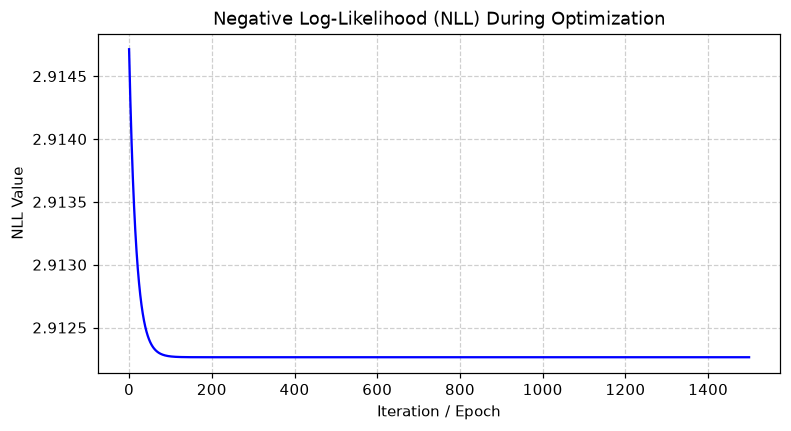

In [27]:
# VISUALIZATION 1: Dixon-Coles Optimization Loss Curve
plt.figure(figsize=(8, 4))
plt.plot(loss_arr, color="b", linestyle="-", linewidth=1.5)

plt.title("Negative Log-Likelihood (NLL) During Optimization")
plt.xlabel("Iteration / Epoch")
plt.ylabel("NLL Value")
plt.grid(True, linestyle="--", alpha=0.6)

# Display the plot
plt.show()

In [28]:
# Test actual goals
home_goals = y_goals_test[:, 0]
away_goals = y_goals_test[:, 1]

# Independent Poisson log probabilities
log_prob_h = (
    -lamda_test_h
    + home_goals * z_test_h
    - gammaln(home_goals + 1)
)

log_prob_a = (
    -lamda_test_a
    + away_goals * z_test_a
    - gammaln(away_goals + 1)
)

# Create NEW masks using TEST data
mask_00 = (home_goals == 0) & (away_goals == 0)
mask_01 = (home_goals == 0) & (away_goals == 1)
mask_10 = (home_goals == 1) & (away_goals == 0)
mask_11 = (home_goals == 1) & (away_goals == 1)

# Dixon-Coles correction
tau = np.ones(len(home_goals))

tau[mask_00] = (
    1 - lamda_test_h[mask_00] * lamda_test_a[mask_00] * rho
)

tau[mask_01] = 1 + lamda_test_h[mask_01] * rho

tau[mask_10] = 1 + lamda_test_a[mask_10] * rho

tau[mask_11] = 1 - rho

# Joint Dixon-Coles NLL
dc_nll = -np.mean(
    log_prob_h + log_prob_a + np.log(np.maximum(tau, 1e-12))
)

poisson_nll = -np.mean(log_prob_h + log_prob_a)

print("Dixon-Coles Test NLL:", dc_nll)
print("Independent Poisson Test NLL:", poisson_nll)

print("Shapes:")
print("Home lambda:", lamda_test_h.shape)
print("Away lambda:", lamda_test_a.shape)
print("Tau:", tau.shape)

Dixon-Coles Test NLL: 2.923295
Independent Poisson Test NLL: 2.924674
Shapes:
Home lambda: (760,)
Away lambda: (760,)
Tau: (760,)

In [29]:
print("Number of 0-0:", np.sum(mask_00))
print("Number of 0-1:", np.sum(mask_01))
print("Number of 1-0:", np.sum(mask_10))
print("Number of 1-1:", np.sum(mask_11))

print("Mean tau:", np.mean(tau))
print("Minimum tau:", np.min(tau))
print("Maximum tau:", np.max(tau))
print("Rho:", rho)

Number of 0-0: 43
Number of 0-1: 57
Number of 1-0: 51
Number of 1-1: 92
Mean tau: 1.0019
Minimum tau: 0.8919
Maximum tau: 1.1011
Rho: -0.04173

In [30]:
from scipy.stats import poisson

log_pois = (
    poisson.logpmf(home_goals, lamda_test_h)
    + poisson.logpmf(away_goals, lamda_test_a)
)

log_dc = log_pois + np.log(np.maximum(tau, 1e-12))

masks = {
    "0-0": mask_00,
    "0-1": mask_01,
    "1-0": mask_10,
    "1-1": mask_11
}

for score, mask in masks.items():
    if np.any(mask):
        print(f"\nScore {score}")
        print("Matches:", np.sum(mask))
        print("Poisson NLL:", -np.mean(log_pois[mask]))
        print("Dixon-Coles NLL:", -np.mean(log_dc[mask]))

Score 0-0
Matches: 43
Poisson NLL: 2.8939
Dixon-Coles NLL: 2.8150

Score 0-1
Matches: 57
Poisson NLL: 2.5308
Dixon-Coles NLL: 2.5909

Score 1-0
Matches: 51
Poisson NLL: 2.4497
Dixon-Coles NLL: 2.5022

Score 1-1
Matches: 92
Poisson NLL: 2.2207
Dixon-Coles NLL: 2.1798

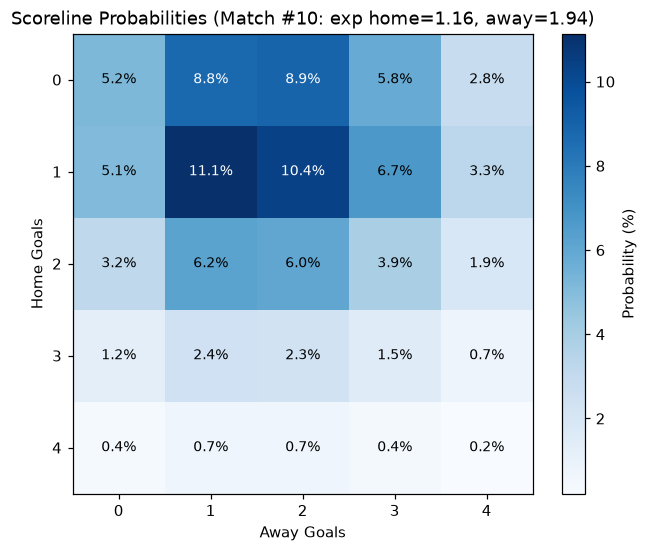

In [31]:
# VISUALIZATION 2: Bivariate Scoreline Probability Heatmap (Sample Match)
# Apply Dixon-Coles adjustment to score matrices
score_matrices_adj = score_matrices.copy()
score_matrices_adj[:, 0, 0] *= (1 - lamda_test_h * lamda_test_a * rho)
score_matrices_adj[:, 0, 1] *= (1 + lamda_test_h * rho)
score_matrices_adj[:, 1, 0] *= (1 + lamda_test_a * rho)
score_matrices_adj[:, 1, 1] *= (1 - rho)
score_matrices_adj /= np.sum(score_matrices_adj, axis=(1, 2), keepdims=True)

# Plot heatmap for a sample test match
sample_idx = 10
fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(score_matrices_adj[sample_idx] * 100, cmap="Blues")
fig.colorbar(cax, label="Probability (%)")

for i in range(5):
    for j in range(5):
        prob_val = score_matrices_adj[sample_idx, i, j] * 100
        ax.text(j, i, f"{prob_val:.1f}%", ha="center", va="center",
                color="white" if prob_val > 8 else "black", fontsize=9)

ax.set_xticks(range(5))
ax.set_yticks(range(5))
ax.set_xlabel("Away Goals")
ax.set_ylabel("Home Goals")
ax.set_title(f"Scoreline Probabilities (Match #{sample_idx}: exp home={lamda_test_h[sample_idx]:.2f}, away={lamda_test_a[sample_idx]:.2f})")
plt.tight_layout()
plt.show()

In [32]:
# Calculate exact score guessing accuracy on test data
flat_matrices = score_matrices_adj.reshape(len(y_goals_test), 25)
indices = np.argmax(flat_matrices, axis=1)

home_pred, away_pred = np.unravel_index(indices, (5, 5))
score_pred = np.column_stack((home_pred, away_pred))

# 1. Exact score accuracy (both home and away goals matched)
correct = np.all(score_pred == y_goals_test, axis=1)
accuracy = np.mean(correct)

# 2. Top-3 most likely scorelines hit rate
top3_idx = np.argsort(-flat_matrices, axis=1)[:, :3]
actual_flat_idx = (y_goals_test[:, 0] * 5 + y_goals_test[:, 1]).astype(int)
top3_hit = np.any(top3_idx == actual_flat_idx[:, None], axis=1)
top3_accuracy = np.mean(top3_hit)

# 3. Match outcome (1X2) accuracy from score guess
pred_outcome = np.where(home_pred > away_pred, 'H', np.where(home_pred == away_pred, 'D', 'A'))
actual_outcome = np.where(y_goals_test[:, 0] > y_goals_test[:, 1], 'H', 
                          np.where(y_goals_test[:, 0] == y_goals_test[:, 1], 'D', 'A'))
outcome_accuracy = np.mean(pred_outcome == actual_outcome)

# 4. Baseline: always guessing 1-1 (most common scoreline)
naive_11 = np.mean((y_goals_test[:, 0] == 1) & (y_goals_test[:, 1] == 1))

print("=" * 55)
print("SCORELINE PREDICTION ACCURACY ON TEST DATA")
print("=" * 55)
print(f"Total Test Matches:          {len(y_goals_test)}")
print(f"Exact Score Accuracy (Top 1): {accuracy * 100:.2f}% ({np.sum(correct)} / {len(y_goals_test)})")
print(f"Top 3 Scorelines Hit Rate:   {top3_accuracy * 100:.2f}% ({np.sum(top3_hit)} / {len(y_goals_test)})")
print(f"1X2 Outcome Accuracy:        {outcome_accuracy * 100:.2f}% ({np.sum(pred_outcome == actual_outcome)} / {len(y_goals_test)})")
print(f"Baseline (Always Guess 1-1): {naive_11 * 100:.2f}%")
print(f"Random Guess (1/25):         4.00%")
print("=" * 55)

SCORELINE PREDICTION ACCURACY ON TEST DATA
Total Test Matches:          760
Exact Score Accuracy (Top 1): 11.71% (89 / 760)
Top 3 Scorelines Hit Rate:   30.79% (234 / 760)
1X2 Outcome Accuracy:        33.82% (257 / 760)
Baseline (Always Guess 1-1): 12.11%
Random Guess (1/25):         4.00%